In [2]:
import numpy as np
import cvxpy as cp
import seaborn as sns
import random
random.seed(4)
np.random.seed(6)
def group_lasso_norm(beta):  # beta_bp
    """Computes the group basis pursuit loss of the matrix beta"""
    output = np.linalg.norm(beta, axis=1).sum()
    return output


def group_basis_pursuit(
    matrix,
    eps=1e-12,
    threshold=1e-6,
    max_iters = 2500,
    seed = 0,
):
    D,P = matrix.shape
    np.random.seed(seed)
    initialization = np.random.randn(P, D)
    print(initialization)
#     beta = cp.Variable((P, D), value=initialization)  # Random initialization
    beta = cp.Variable((P,D))  # could initialize with lasso?
#     beta.value = np.asarray([[1.,0], [0,1.],[0,0],[0,0]])
    objective = cp.Minimize(cp.sum(cp.norm(beta, axis=1)))
    constraints = [matrix @ beta == np.identity(D)]
    problem = cp.Problem(objective, constraints)
    scs_opts = {"eps": eps, "max_iters": max_iters, "scale": 10.}
    output = problem.solve(solver=cp.SCS, **scs_opts)
#     output = problem.solve(solver = cp.ECOS)
    if output is np.inf:
        raise ValueError("No solution found")
    beta_optimized = beta.value
    beta_sparse = beta_optimized.copy()
    beta_sparse[np.abs(beta_sparse) < threshold] = 0
    return beta_sparse

from scipy.stats import ortho_group
D = 2
P = 10
betas = []
# the next 3 lines were instide the loop to create the snoot
data = np.random.multivariate_normal(np.zeros(P), np.identity(P), D)
data = data / np.linalg.norm(data, axis = 0)
data[:,:D] = np.identity(D)

# asdf = ortho_group(2)
# data[:,:D] = asdf.rvs(1) #scipy.stats.
print(data[:D,:D])
for s in range(2):
    beta = group_basis_pursuit(data, eps = 1e-16, max_iters = 100000, seed = s*5)
    betas.append(beta)
    
beta_true = np.zeros(beta.shape)
beta_true[0,0] = 1
beta_true[1,1] = 1

[[1. 0.]
 [0. 1.]]
[[ 1.76405235  0.40015721]
 [ 0.97873798  2.2408932 ]
 [ 1.86755799 -0.97727788]
 [ 0.95008842 -0.15135721]
 [-0.10321885  0.4105985 ]
 [ 0.14404357  1.45427351]
 [ 0.76103773  0.12167502]
 [ 0.44386323  0.33367433]
 [ 1.49407907 -0.20515826]
 [ 0.3130677  -0.85409574]]
[[ 0.44122749 -0.33087015]
 [ 2.43077119 -0.25209213]
 [ 0.10960984  1.58248112]
 [-0.9092324  -0.59163666]
 [ 0.18760323 -0.32986996]
 [-1.19276461 -0.20487651]
 [-0.35882895  0.6034716 ]
 [-1.66478853 -0.70017904]
 [ 1.15139101  1.85733101]
 [-1.51117956  0.64484751]]


In [3]:
from sklearn.metrics.pairwise import cosine_similarity

<Axes: >

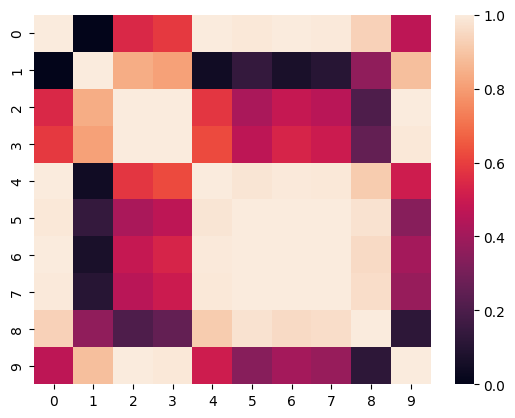

In [9]:
import seaborn as sns
sns.heatmap(np.abs(cosine_similarity(data.transpose())))

In [10]:
print(np.abs(cosine_similarity(data.transpose())))

[[1.         0.         0.54410606 0.58770936 0.999003   0.99014785
  0.99772661 0.99479233 0.932633   0.46850331]
 [0.         1.         0.83901644 0.80907213 0.04464301 0.14002586
  0.06739153 0.10192259 0.36082639 0.88346174]
 [0.54410606 0.83901644 1.         0.99860105 0.58101981 0.42126145
  0.4863265  0.45575781 0.20471199 0.99615442]
 [0.58770936 0.80907213 0.99860105 1.         0.62324283 0.46862813
  0.53184866 0.50218604 0.25618257 0.99012805]
 [0.999003   0.04464301 0.58101981 0.62324283 1.         0.9829095
  0.99372332 0.9892504  0.91559479 0.5074766 ]
 [0.99014785 0.14002586 0.42126145 0.46862813 0.9829095  1.
  0.99733341 0.99926328 0.97396958 0.34018005]
 [0.99772661 0.06739153 0.4863265  0.53184866 0.99372332 0.99733341
  1.         0.9993995  0.9548294  0.40790038]
 [0.99479233 0.10192259 0.45575781 0.50218604 0.9892504  0.99926328
  0.9993995  1.         0.96455252 0.37601879]
 [0.932633   0.36082639 0.20471199 0.25618257 0.91559479 0.97396958
  0.9548294  0.964552

In [11]:
# if there are so many solutions, why are they the same each time?
# we don't actually know if its star convex, cause we only got two solutions. LOLOL 

In [12]:
# okay we gotta check for star convexity
def sample_path(beta_1, beta_2, npoints = 100):
    
    ps = np.linspace(0,1, npoints)
    losses = []
    constraint_violations = []
    for p in ps:
        beta_parametrized = p * beta_1 + (1 - p) *  beta_2

        losses.append(2 - group_lasso_norm(beta_parametrized))
        constraint_violations.append(np.linalg.norm(np.identity(D) - data @ (beta_parametrized)))
    #     sns.heatmap(np.abs((beta_true + beta)/ 2))
    
    return constraint_violations, losses



Text(0.5, 0, 'losses')

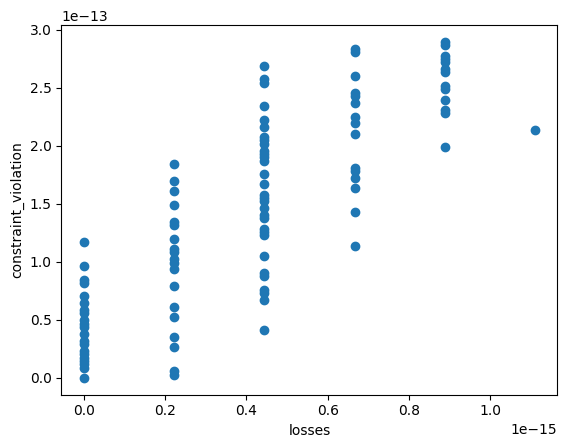

In [14]:
# the constraint set is convex was the idea but there is something curvy here!
constraint_violations, losses= sample_path(betas[0], beta_true)

import matplotlib.pyplot as plt
plt.scatter(losses, constraint_violations)
plt.ylabel('constraint_violation')
plt.xlabel('losses')


In [29]:
beta_proj, Y_proj = project_onto_constraint(np.identity(D), data, betas[0])

Text(0.5, 0, 'losses')

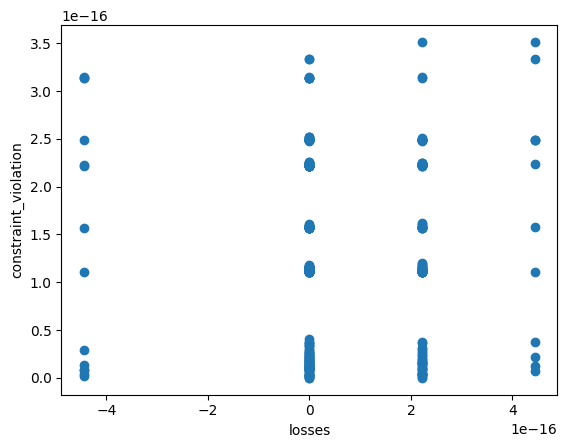

In [36]:
# but there is nothing curvy here, so it looks like its truly not strongly convex?
constraint_violations, losses= sample_path(beta_proj, beta_true, 400)

import matplotlib.pyplot as plt
plt.scatter(losses, constraint_violations)
plt.ylabel('constraint_violation')
plt.xlabel('losses')

In [33]:
beta_proj

array([[ 5.86729292e-02,  3.14249460e-16],
       [ 8.98192128e-14,  6.31365096e-01],
       [ 7.05954556e-02, -1.08858828e-01],
       [-4.96363867e-02,  6.83321041e-02],
       [-2.18363497e-02,  9.75813249e-04],
       [ 1.85304844e-01,  2.62056523e-02],
       [ 1.18161748e-01,  7.98124502e-03],
       [-1.49848774e-01, -1.53529280e-02],
       [ 3.81350252e-01,  1.47540603e-01],
       [-9.78194881e-02,  1.84459264e-01]])

Text(0.5, 0, 'losses')

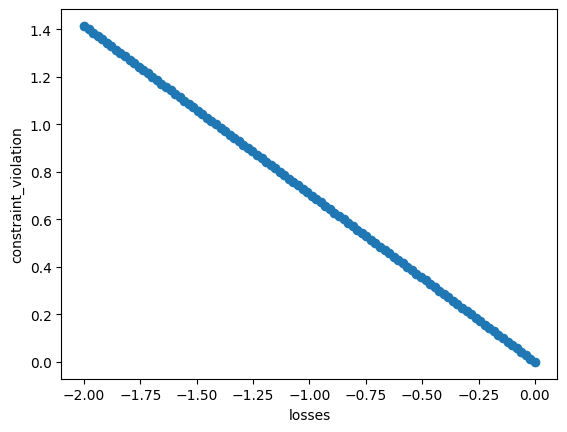

In [19]:
# if we continue we get a line wutttt
constraint_violations, losses= sample_path( beta_proj+ beta_true , beta_true)

import matplotlib.pyplot as plt
plt.scatter(losses, constraint_violations)
plt.ylabel('constraint_violation')
plt.xlabel('losses')


In [20]:
print((2 - group_lasso_norm(betas[0])))
constraint_violation = np.linalg.norm(np.identity(D) - data @ (betas[0]))

8.881784197001252e-16


Text(0.5, 0, 'losses')

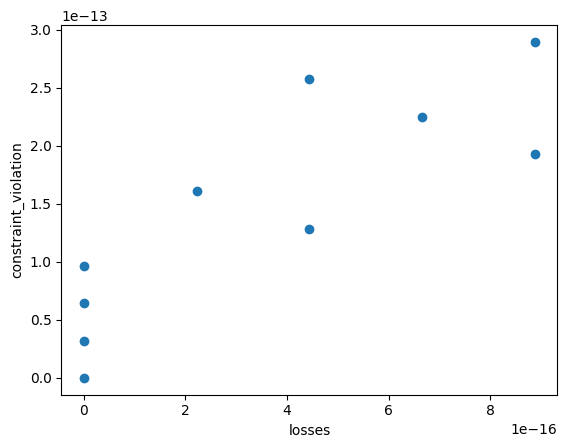

In [32]:
# why is this one so much worse?

constraint_violations, losses = sample_path(betas[0], beta_true,10)

import matplotlib.pyplot as plt
plt.scatter(losses, constraint_violations)
plt.ylabel('constraint_violation')
plt.xlabel('losses')

In [16]:
import numpy as np

def project_onto_constraint(Y, X, beta_hat):
    # Compute the residual R = X beta_hat - Y
    R = X @ beta_hat - Y  # Dimensions: (n x m)
    
    # Compute M = X X^T
    M = X @ X.T  # Dimensions: (n x n)
    
    # Solve M Lambda = R for Lambda (n x m)
    # Use least squares in case M is singular
    Lambda, residuals, rank, s = np.linalg.lstsq(M, R, rcond=None)
    
    # Compute beta_proj = beta_hat - X^T Lambda
    beta_proj = beta_hat - X.T @ Lambda  # Dimensions: (p x m)
    
    # Compute Y_proj = X beta_proj
    Y_proj = X @ beta_proj  # Dimensions: (n x m)
    
    return beta_proj, Y_proj


In [23]:
beta_proj, Y_proj = project_onto_constraint(np.identity(D), data, beta)

In [2]:
import numpy as np
print(np.linalg.norm(beta_proj, axis = 1))
# print(len(selected_indices), "number of selected coefficients")
print(2 - group_lasso_norm(beta_proj), "loss improvement over naive solution")
print(np.linalg.norm(np.identity(D) - data @ beta_proj), "constraint violation")
sns.heatmap(np.abs(beta_proj))

NameError: name 'beta_proj' is not defined

0.0 loss improvement over naive solution
0.0 constraint violation


<Axes: >

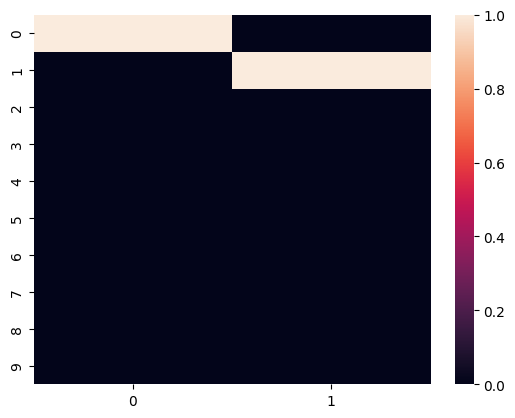

In [25]:
beta_true = np.zeros(beta_proj.shape)
beta_true[0,0] = 1
beta_true[1,1] = 1
print(2 - group_lasso_norm(beta_true), "loss improvement over naive solution")
print(np.linalg.norm(np.identity(D) - data @ beta_true), "constraint violation")
sns.heatmap(np.abs(beta_true))

In [43]:

def sample_alpha(alpha_min, alpha_max, large_value=1e6):
    """
    Sample alpha from the uniform distribution between alpha_min and alpha_max,
    handling cases where the limits are infinite.
    """
    # Replace infinite values with large finite bounds
    if alpha_min == -np.inf:
        alpha_min = -large_value
    if alpha_max == np.inf:
        alpha_max = large_value
    
    # Sample uniformly between the limits
    return np.random.uniform(alpha_min, alpha_max)


In [94]:
import numpy as np
from numpy.linalg import norm

def null_space(X, rtol=1e-5):
    """
    Computes the null space of a matrix X using SVD.
    Parameters:
        X (np.array): Input matrix
        rtol (float): Relative tolerance for small singular values
    Returns:
        Null space of X (np.array): The directions that span the null space of X
    """
    X = X.transpose()
    U, S, Vh = svd(X)
    rank = (S > rtol * S[0]).sum()  # Compute effective rank based on tolerance
    null_space = Vh[rank:].T  # Null space is the bottom part of Vh (from SVD)
    return null_space

def hit_and_run_sampler(X, y, b0, num_samples=1000):
    """
    Hit-and-Run algorithm for sampling from the convex set defined by:
    argmin ||b||_{1,2} : y = Xb
    Parameters:
        X (np.array): The matrix in the constraint y = Xb
        y (np.array): The vector in the constraint y = Xb
        b0 (np.array): Initial point within the feasible set (must satisfy y = Xb)
        num_samples (int): Number of samples to generate
    Returns:
        samples (list): List of sampled points b within the feasible region
    """
    
    def compute_step_limits(X, b, d):
        """
        Compute the feasible step limits along the direction d for the hit-and-run algorithm.
        We find the largest step size that keeps the point within the constraint y = Xb.
        """
        # Perform matrix multiplication with einsum to avoid flattening
        r = y - np.einsum('ij,jk->ik', X, b)  # X @ b using einsum
        Xd = np.einsum('ij,jk->ik', X, d)     # X @ d using einsum

        if np.allclose(Xd, 0):
            # If Xd is close to zero, return very large limits (direction does not affect feasibility)
            return -np.inf, np.inf
        
        # Compute feasible step range based on the solution to y = X(b + alpha * d)
        alpha_min = -np.inf
        alpha_max = np.inf
        
        return alpha_min, alpha_max

#     def random_direction(b):
#         """Generate a random direction with the same shape as b."""
#         d = np.random.randn(*b.shape)  # Random direction with the same shape as b
#         return d  # Normalize to get a unit direction
    def random_direction(null_space):
        """
        Generate a random direction from the null space.
        Parameters:
            null_space (np.array): The null space of matrix X
        Returns:
            A random direction within the null space.
        """
        # Random linear combination of null space directions
        print(null_space.shape)
        d = null_space @ np.random.randn(null_space.shape[1])
        print(d.shape, 'dshape')
        return d / norm(d)  # Normalize the direction

    
    # Initialize with the feasible point b0
    b = b0.copy()
    samples = [b0]
    
    for i in range(num_samples):
        # Step 1: Generate a random direction d with the same shape as b
        d = random_direction(b)
        
        # Step 2: Compute feasible step limits based on y = Xb constraint
        alpha_min, alpha_max = compute_step_limits(X, b, d)
        alpha = sample_alpha(alpha_min, alpha_max)

        # Step 3: Update the point b -> b + alpha * d
        b_new = b + alpha * d  # Both b and d are now 2D arrays with compatible shapes
        
        # Step 4: Check if the new point improves the objective (minimizing ||b||_{1,2})
        if group_lasso_norm(b_new) <= group_lasso_norm(b):
            b = b_new  # Accept the new point if it improves the objective
        
        samples.append(b)
    
    return np.array(samples)


In [95]:
samples = hit_and_run_sampler(data, np.identity(D), beta_proj, num_samples=1000)
print(samples[0], samples[1])

(10, 2)
(10,) dshape


ValueError: einstein sum subscripts string contains too many subscripts for operand 1

In [74]:
# samples, constraint_violations_per_sample, losses_per_sample = hit_and_run_sampler(X, y, b0, num_samples=1000)

# Post-hoc function to compute constraint violations and losses for all pairs of samples
def compute_constraint_violations_and_losses(samples, data, D, npoints=100):
    """
    Computes constraint violations and losses for all pairs of consecutive samples.
    
    Parameters:
        samples: np.array - Generated samples from the hit-and-run sampler.
        data: np.array - Data matrix.
        D: int - Dimension of the identity matrix.
        npoints: int - Number of points to sample along the path.
    
    Returns:
        all_constraint_violations: list - Constraint violations for each sample path.
        all_losses: list - Losses for each sample path.
    """
    all_constraint_violations = []
    all_losses = []
    
    for i in range(1, len(samples)):
        beta_1 = samples[i-1]
        beta_2 = samples[i]
        
        # Compute the path between the two samples and their constraint violations and losses
        constraint_violations, losses = sample_path(beta_1, beta_2, data, D, npoints)
        
        all_constraint_violations.append(constraint_violations)
        all_losses.append(losses)
    
    return all_constraint_violations, all_losses


In [75]:

# Post-hoc function to compute constraint violations and losses for each sample
def compute_constraint_violations_and_losses(samples, data, D):
    """
    Computes constraint violations and losses for each sample generated by hit-and-run.
    
    Parameters:
        samples: np.array - Generated samples from the hit-and-run sampler.
        data: np.array - Data matrix.
        D: int - Dimension of the identity matrix.
    
    Returns:
        constraint_violations: list - Constraint violations for each sample.
        losses: list - Losses for each sample.
    """
    losses = []
    constraint_violations = []
    
    for sample in samples:
        # Compute the loss for the current sample
        loss = 2 - group_lasso_norm(sample)
        losses.append(loss)
        
        # Compute the constraint violation for the current sample
        violation = np.linalg.norm(np.identity(D) - data @ sample)
        constraint_violations.append(violation)
    
    return constraint_violations, losses


In [78]:
constraint_violations_per_sample, losses_per_sample = compute_constraint_violations_and_losses(samples, data, data.shape[0])


In [81]:
samples[0]

array([[ 5.86729292e-02,  3.14249460e-16],
       [ 8.98192128e-14,  6.31365096e-01],
       [ 7.05954556e-02, -1.08858828e-01],
       [-4.96363867e-02,  6.83321041e-02],
       [-2.18363497e-02,  9.75813249e-04],
       [ 1.85304844e-01,  2.62056523e-02],
       [ 1.18161748e-01,  7.98124502e-03],
       [-1.49848774e-01, -1.53529280e-02],
       [ 3.81350252e-01,  1.47540603e-01],
       [-9.78194881e-02,  1.84459264e-01]])

In [84]:
samples[1000]

array([[ 5.86729292e-02,  3.14249460e-16],
       [ 8.98192128e-14,  6.31365096e-01],
       [ 7.05954556e-02, -1.08858828e-01],
       [-4.96363867e-02,  6.83321041e-02],
       [-2.18363497e-02,  9.75813249e-04],
       [ 1.85304844e-01,  2.62056523e-02],
       [ 1.18161748e-01,  7.98124502e-03],
       [-1.49848774e-01, -1.53529280e-02],
       [ 3.81350252e-01,  1.47540603e-01],
       [-9.78194881e-02,  1.84459264e-01]])

0.0 loss improvement over naive solution
0.6503614308478831 constraint violation


<Axes: >

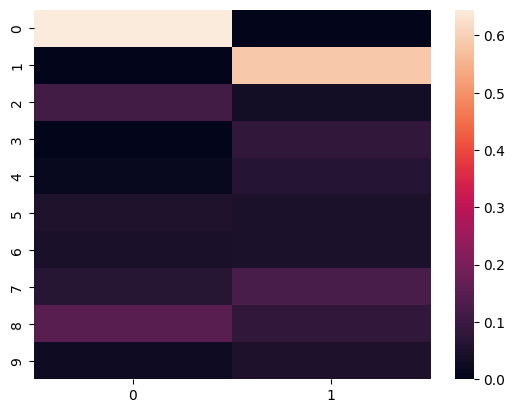

In [178]:
print(2 - group_lasso_norm((beta_true + beta_proj)/ 2), "loss improvement over naive solution")
print(np.linalg.norm(np.identity(D) - data @ ((beta_true + beta_proj)/ 2)), "constraint violation")
sns.heatmap(np.abs((beta_true + beta_proj)/ 2))

In [179]:
# so it looks like the "solutions" for a convex set - but what about movement in a random direction?

# could i look at the gradient with respect to different directions of the penalty?
# theoretically, practically (i.e. with autograd)?

2.220446049250313e-16 loss improvement over naive solution
1.4473748760377157e-13 constraint violation


<Axes: >

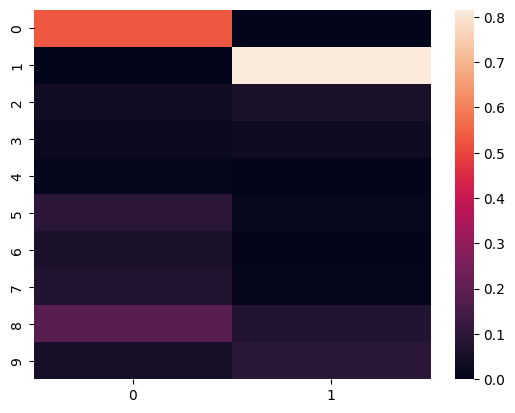

In [180]:
print(2 - group_lasso_norm((beta_true + beta)/ 2), "loss improvement over naive solution")
print(np.linalg.norm(np.identity(D) - data @ ((beta_true + beta)/ 2)), "constraint violation")
sns.heatmap(np.abs((beta_true + beta)/ 2))

In [156]:
# this is a false idol... project back on the constraint set like chatgpt told you to.

ps = np.linspace(0,1, 100)
losses = []
constraint_violations = []
for p in ps:
    beta_parametrized = p * beta_true + (1 - p) *  beta

    losses.append(2 - group_lasso_norm(beta_parametrized))
    constraint_violations.append(np.linalg.norm(np.identity(D) - data @ (beta_parametrized)))
#     sns.heatmap(np.abs((beta_true + beta)/ 2))

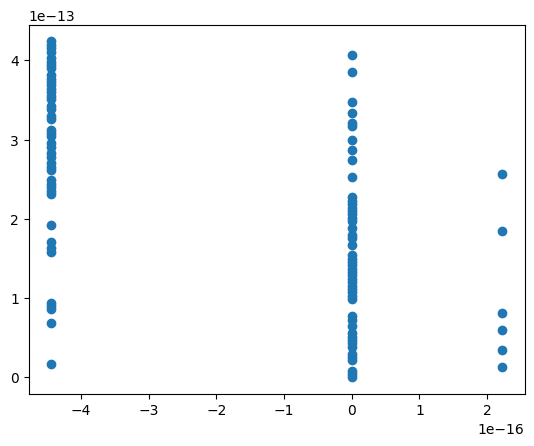

In [157]:
import matplotlib.pyplot as plt
plt.scatter(losses, constraint_violations)
# plt.xbale('')

In [12]:
??cp.Minimize

In [13]:
loss_improvements = []
constraint_violations = []
logspace_iters = np.logspace(1, 4, num=10, dtype=int)  # Iterations from 100 to 100000

for max_iters in logspace_iters:
    beta = group_basis_pursuit(data, eps=1e-16, max_iters=max_iters)
    selected_indices = np.where(np.linalg.norm(beta, axis=1))[0]
    loss_improvement = 2 - group_lasso_norm(beta)
    constraint_violation = np.linalg.norm(np.identity(D) - data @ beta)
    
    # Store results
    loss_improvements.append(loss_improvement)
    constraint_violations.append(constraint_violation)



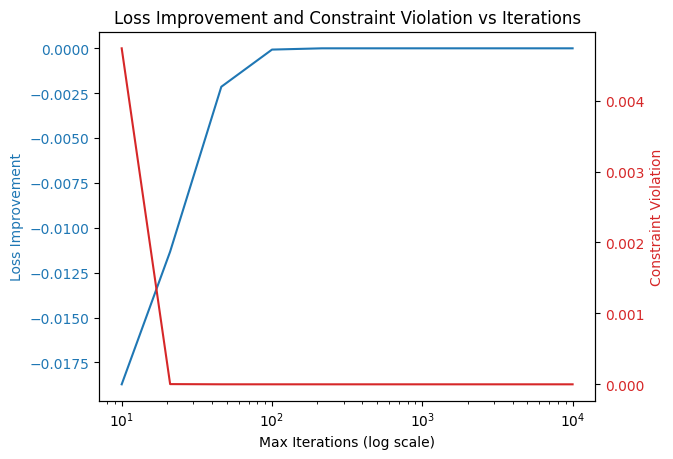

In [36]:
import matplotlib.pyplot as plt
# Plotting
fig, ax1 = plt.subplots()

ax1.set_xlabel('Max Iterations (log scale)')
ax1.set_xscale('log')
# ax1.set_yscale('log')
# Plot loss improvement
ax1.set_ylabel('Loss Improvement', color='tab:blue')
ax1.plot(logspace_iters, loss_improvements, color='tab:blue', label='Loss Improvement')
ax1.tick_params(axis='y', labelcolor='tab:blue')

# Create another y-axis for constraint violation
ax2 = ax1.twinx()
ax2.set_ylabel('Constraint Violation', color='tab:red')
ax2.plot(logspace_iters, constraint_violations, color='tab:red', label='Constraint Violation')
ax2.tick_params(axis='y', labelcolor='tab:red')

plt.title('Loss Improvement and Constraint Violation vs Iterations')
plt.show()

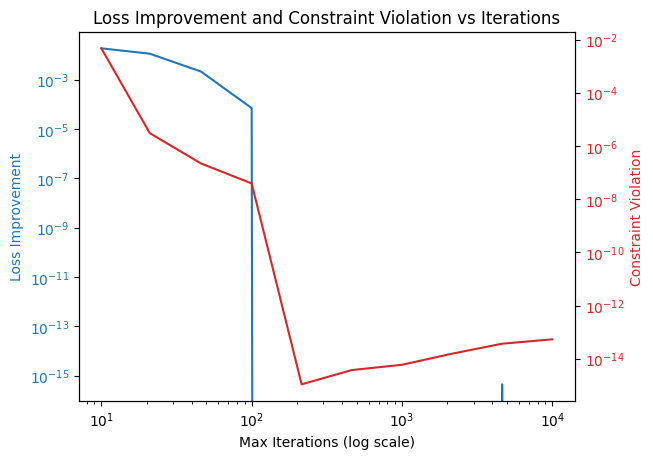

In [39]:
import matplotlib.pyplot as plt
# Plotting
fig, ax1 = plt.subplots()

ax1.set_xlabel('Max Iterations (log scale)')
ax1.set_xscale('log')
# ax1.set_yscale('log')
# Plot loss improvement
ax1.set_ylabel('Loss Improvement', color='tab:blue')
ax1.set_yscale('log')

ax1.plot(logspace_iters, -np.asarray(loss_improvements), color='tab:blue', label='Loss Improvement')
ax1.tick_params(axis='y', labelcolor='tab:blue')

# Create another y-axis for constraint violation
ax2 = ax1.twinx()
ax2.set_ylabel('Constraint Violation', color='tab:red')
ax2.plot(logspace_iters, constraint_violations, color='tab:red', label='Constraint Violation')
ax2.tick_params(axis='y', labelcolor='tab:red')
ax2.set_yscale('log')


plt.title('Loss Improvement and Constraint Violation vs Iterations')
plt.show()

In [31]:
# a preconditioning approach - doesn't seem to help.

import numpy as np
import cvxpy as cp

def group_lasso_norm(beta):  # beta_bp
    """Computes the group basis pursuit loss of the matrix beta"""
    output = np.linalg.norm(beta, axis=1).sum()
    return output

import numpy as np




# Perform QR decomposition


# Undo the QR decomposition to get the original solution



def group_basis_pursuit(
    matrix,
    eps=1e-12,
    threshold=1e-6,
    max_iters = 2500,
):

    D,P = matrix.shape
    Q, R = np.linalg.qr(matrix)
#     print(R.shape)
    beta = cp.Variable((P,D))  # could initialize with lasso?
    beta.value = np.asarray([[1.,0], [0,1.],[0,0],[0,0]])
    objective = cp.Minimize(cp.sum(cp.norm(beta, axis=1)))
    constraints = [R @ beta == np.identity(D)]
    problem = cp.Problem(objective, constraints)
    scs_opts = {"eps": eps, "max_iters": max_iters, "scale": 10.}
    output = problem.solve(solver=cp.SCS, **scs_opts)
#     output = problem.solve(solver= cp.CVXOPT)
    if output is np.inf:
        raise ValueError("No solution found")
#     print(beta.value.shape)
    print(Q.shape)
    beta_new = beta.value  @ Q
#     print(beta_new.shape)
    beta_sparse = beta_new.copy()
    beta_sparse[np.abs(beta_sparse) < threshold] = 0
    return beta_sparse


np.random.seed(0)
D = 2
P = 4
data = np.random.multivariate_normal(np.zeros(P), np.identity(P), D)
data = data / np.linalg.norm(data, axis = 0)
data[:,:D] = np.identity(D)
beta = group_basis_pursuit(data, eps = 1e-16, max_iters = 100000)
selected_indices = np.where(np.linalg.norm(beta, axis = 1))[0]
print(len(selected_indices), "number of selected coefficients")
print(2 - group_lasso_norm(beta), "loss improvement over naive solution")
print(np.linalg.norm(np.identity(D) - data @ beta), "constraint violation")

(2, 2)
4 number of selected coefficients
0.0 loss improvement over naive solution
1.2421393940826047e-13 constraint violation


In [27]:
beta.shape

(4, 4)

In [ ]:
# NOTE (Sam):
# randomly resampling the data for every run make it look like a nose
# as parametrized by the path between as it vary from another datasets solution to that one.
# the interesting thing is it can even be linear (case betas[0], betas[5])
# and losses stayed constrait.
# this basically means there are 
# i thought looks star convex.  Why is 5 different?  Small loss but big constraint violation

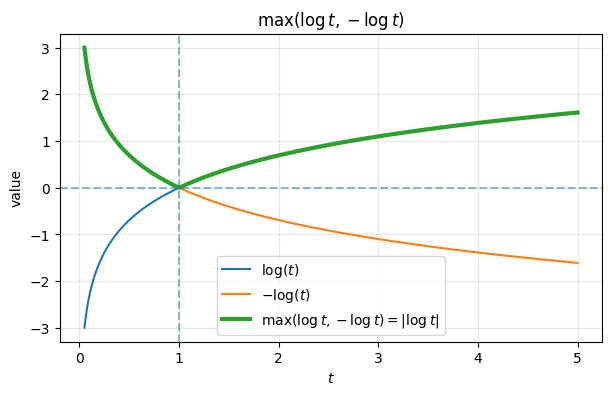

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# t > 0
t = np.linspace(0.05, 5, 1000)

y1 = np.log(t)
y2 = -np.log(t)
y_max = np.maximum(y1, y2)

plt.figure(figsize=(7, 4))
plt.plot(t, y1, label=r'$\log(t)$')
plt.plot(t, y2, label=r'$-\log(t)$')
plt.plot(t, y_max, linewidth=3, label=r'$\max(\log t, -\log t)=|\log t|$')

plt.axvline(1, linestyle='--', alpha=0.5)
plt.axhline(0, linestyle='--', alpha=0.5)

plt.xlabel(r'$t$')
plt.ylabel('value')
plt.title(r'$\max(\log t, -\log t)$')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

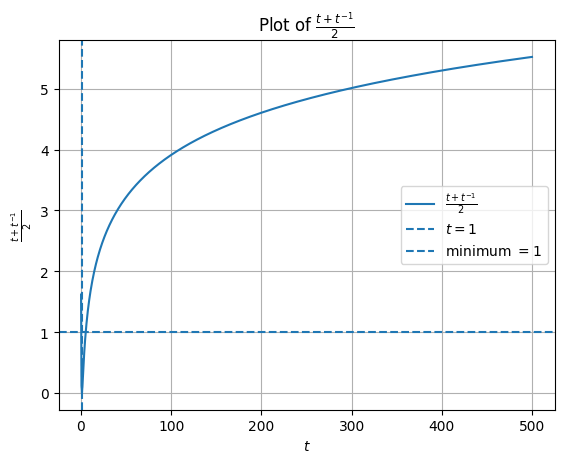

In [11]:
import numpy as np
import matplotlib.pyplot as plt

# t must be positive; avoid t = 0
t = np.linspace(0.1, 500, 1000)

f = np.log((t + 1/t) / 2)

plt.plot(t, f, label=r"$\frac{t + t^{-1}}{2}$")
plt.axvline(1, linestyle="--", label=r"$t=1$")
plt.axhline(1, linestyle="--", label=r"minimum $=1$")

plt.xlabel(r"$t$")
plt.ylabel(r"$\frac{t + t^{-1}}{2}$")
plt.title(r"Plot of $\frac{t + t^{-1}}{2}$")
plt.legend()
plt.grid(True)
plt.show()

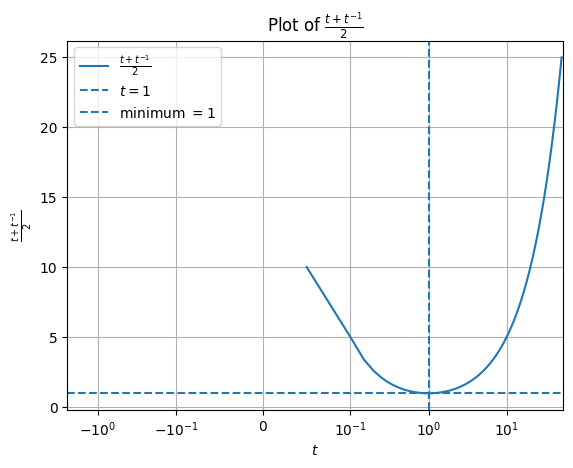

In [8]:
import numpy as np
import matplotlib.pyplot as plt

# t must be positive; avoid t = 0
t = np.linspace(0.05, 50, 1000)

f = (t + 1/t) / 2

plt.plot(t, f, label=r"$\frac{t + t^{-1}}{2}$")
plt.axvline(1, linestyle="--", label=r"$t=1$")
plt.axhline(1, linestyle="--", label=r"minimum $=1$")
plt.xscale("symlog", linthresh=0.1)
plt.xlabel(r"$t$")
plt.ylabel(r"$\frac{t + t^{-1}}{2}$")
plt.title(r"Plot of $\frac{t + t^{-1}}{2}$")
plt.legend()
plt.grid(True)
plt.show()

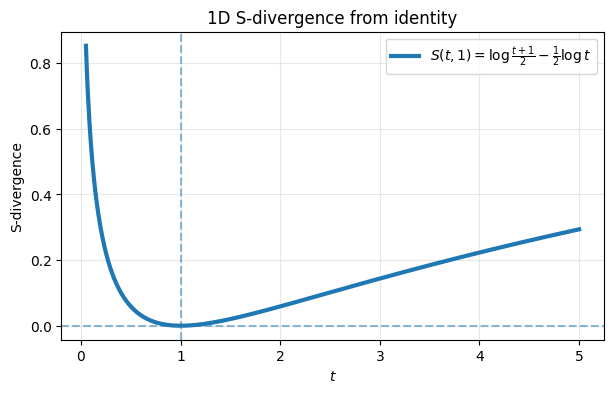

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Positive scalar t = Gram eigenvalue
t = np.linspace(0.05, 5, 1000)

# 1D S-divergence from identity: S(t, 1)
S_t = np.log((t + 1) / 2) - 0.5 * np.log(t)

plt.figure(figsize=(7, 4))
plt.plot(t, S_t, linewidth=3, label=r'$S(t,1)=\log\frac{t+1}{2}-\frac{1}{2}\log t$')
plt.axvline(1, linestyle='--', alpha=0.5)
plt.axhline(0, linestyle='--', alpha=0.5)

plt.xlabel(r'$t$')
plt.ylabel('S-divergence')
plt.title('1D S-divergence from identity')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()